# 02 · Feature engineering, model selection and tuning
The production entry point is `python -m heart.train` (all runs tracked in MLflow). This notebook documents *why* the final configuration was chosen: baselines, the preprocessing pipeline, validation curves, and the tracked grid-search results.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src")); sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np
pd.set_option("display.width", 140)
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split, validation_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from heart.config import FEATURES, TARGET, RANDOM_STATE
from heart.data import load_clean
from heart.features import build_pipeline, build_preprocessor
df = load_clean()
X, y = df[FEATURES].astype(float), df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(242, 13) (61, 13)


## 1. The preprocessing pipeline
One `ColumnTransformer`, saved *inside* the model so serving applies identical transformations.

In [2]:
pre = build_preprocessor().fit(X_train)
print(pre)
print("\n", len(pre.get_feature_names_out()), "model inputs:", list(pre.get_feature_names_out()))

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['age', 'trestbps', 'chol', 'thalach',
                                  'oldpeak', 'ca']),
                                ('bin', SimpleImputer(strategy='most_frequent'),
                                 ['sex', 'fbs', 'exang']),
                                ('cat',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(categories=[[1.0,
                                                                             2.0,
                                                      

## 2. Baselines with default hyper-parameters (5-fold CV on the training split)

In [3]:
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
candidates = {
    "majority class": build_pipeline(DummyClassifier(strategy="most_frequent")),
    "logistic regression": build_pipeline(LogisticRegression(max_iter=2000)),
    "random forest": build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE), scale_numeric=False),
}
rows = {}
for name, pipe in candidates.items():
    res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    rows[name] = {m: f"{res['test_'+m].mean():.3f} ± {res['test_'+m].std():.3f}" for m in scoring}
pd.DataFrame(rows).T

,accuracy,precision,recall,f1,roc_auc
majority class,0.541 ± 0.006,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.500 ± 0.000
logistic regression,0.839 ± 0.016,0.877 ± 0.071,0.766 ± 0.045,0.814 ± 0.010,0.907 ± 0.018
random forest,0.806 ± 0.023,0.816 ± 0.066,0.756 ± 0.049,0.781 ± 0.020,0.889 ± 0.024


Both learners beat the majority baseline by a wide margin. The default random forest overfits a 242-row training set (fully grown trees), which motivates tuning `max_depth` / `min_samples_leaf`.

## 3. Validation curves: how each key hyper-parameter affects CV ROC-AUC

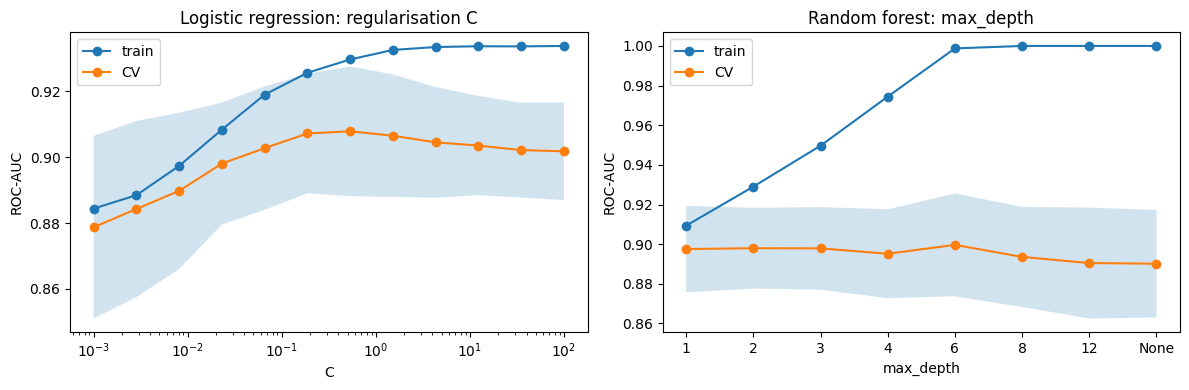

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
Cs = np.logspace(-3, 2, 12)
tr, va = validation_curve(build_pipeline(LogisticRegression(max_iter=5000, solver="liblinear")), X_train, y_train,
                          param_name="model__C", param_range=Cs, cv=cv, scoring="roc_auc")
axes[0].semilogx(Cs, tr.mean(1), "o-", label="train"); axes[0].semilogx(Cs, va.mean(1), "o-", label="CV")
axes[0].fill_between(Cs, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=.2)
axes[0].set(title="Logistic regression: regularisation C", xlabel="C", ylabel="ROC-AUC"); axes[0].legend()
depths = [1, 2, 3, 4, 6, 8, 12, None]
tr, va = validation_curve(build_pipeline(RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1), False),
                          X_train, y_train, param_name="model__max_depth", param_range=depths, cv=cv, scoring="roc_auc")
lbl = [str(d) for d in depths]
axes[1].plot(lbl, tr.mean(1), "o-", label="train"); axes[1].plot(lbl, va.mean(1), "o-", label="CV")
axes[1].fill_between(lbl, va.mean(1)-va.std(1), va.mean(1)+va.std(1), alpha=.2)
axes[1].set(title="Random forest: max_depth", xlabel="max_depth", ylabel="ROC-AUC"); axes[1].legend()
plt.tight_layout(); plt.show()

* Logistic regression is flat for C ≥ 0.1 and only degrades with very strong regularisation → grid C ∈ {0.01 … 10} with L1/L2.
* Random forest training AUC reaches 1.0 for deep trees while CV AUC plateaus around depth 4–8 → grid over depth, leaf size and max_features.

## 4. Tracked grid search (results of `python -m heart.train`)
GridSearchCV, 5-fold stratified CV, refit on ROC-AUC. Every hyper-parameter combination is a nested MLflow run; each model family has a parent run with the best parameters, CV and test metrics, plots and the serialised model.

In [5]:
import json
comparison = pd.read_csv(ROOT / "reports/model_comparison.csv", index_col=0)
cols = [c for c in comparison.columns if c.endswith("_mean") or c.startswith("test_")]
comparison[cols].round(3).T

model,logistic_regression,random_forest,gradient_boosting
cv_accuracy_mean,0.855,0.826,0.822
cv_precision_mean,0.882,0.841,0.830
cv_recall_mean,0.801,0.774,0.783
cv_f1_mean,0.834,0.801,0.800
cv_roc_auc_mean,0.908,0.901,0.879
test_accuracy,0.869,0.885,0.902
test_precision,0.812,0.839,0.867
test_recall,0.929,0.929,0.929
test_f1,0.867,0.881,0.897
test_roc_auc,0.961,0.956,0.954


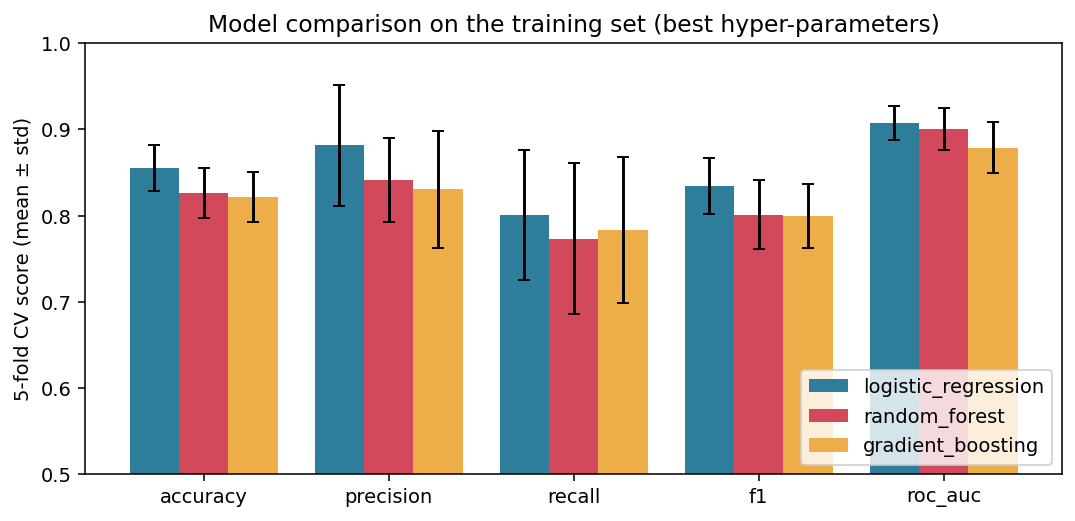

Champion: logistic_regression | best params: {'C': 0.3, 'class_weight': 'balanced', 'penalty': 'l2'}
Selection rule: highest mean 5-fold CV ROC-AUC on the training split


In [6]:
from IPython.display import Image, display
display(Image(filename=str(ROOT / "reports/figures/07_model_comparison.png"), width=760))
meta = json.loads((ROOT / "models/model_metadata.json").read_text())
print("Champion:", meta["algorithm"], "| best params:", meta["best_params"])
print("Selection rule:", meta["selection_rule"])

In [7]:
runs = pd.read_csv(ROOT / "reports/mlflow_runs.csv")
cand = runs[runs["tags.stage"] == "grid-candidate"]
print(len(runs), "MLflow runs in total;", len(cand), "grid candidates")
top = cand.sort_values("metrics.cv_roc_auc_mean", ascending=False)
pcols = [c for c in cand.columns if c.startswith("params.")]
top[["tags.model_type", "metrics.cv_roc_auc_mean", "metrics.cv_recall_mean"] + pcols].head(10).round(3)

142 MLflow runs in total; 136 grid candidates


,tags.model_type,metrics.cv_roc_auc_mean,metrics.cv_recall_mean,params.learning_rate,params.n_estimators,params.max_depth,params.scale_numeric,params.n_train,params.cv_folds,params.n_test,params.n_candidates,params.max_features,params.min_samples_leaf,params.class_weight,params.C,params.penalty
129,logistic_regression,0.907,0.801,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced,0.3,l2
58,logistic_regression,0.907,0.801,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced,0.3,l2
54,logistic_regression,0.907,0.828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced,1.0,l2
125,logistic_regression,0.907,0.828,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced,1.0,l2
127,logistic_regression,0.907,0.774,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,l2
56,logistic_regression,0.907,0.774,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,l2
60,logistic_regression,0.906,0.774,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.3,l2
131,logistic_regression,0.906,0.774,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.3,l2
50,logistic_regression,0.906,0.811,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced,3.0,l2
121,logistic_regression,0.906,0.811,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,balanced,3.0,l2


## 5. Final evaluation of the champion on the held-out test set

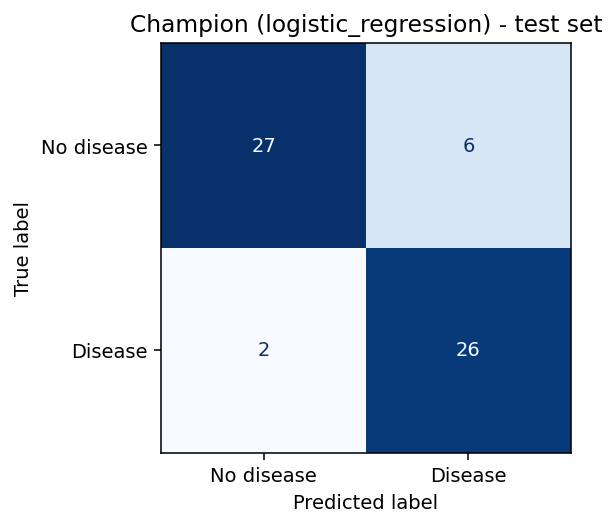

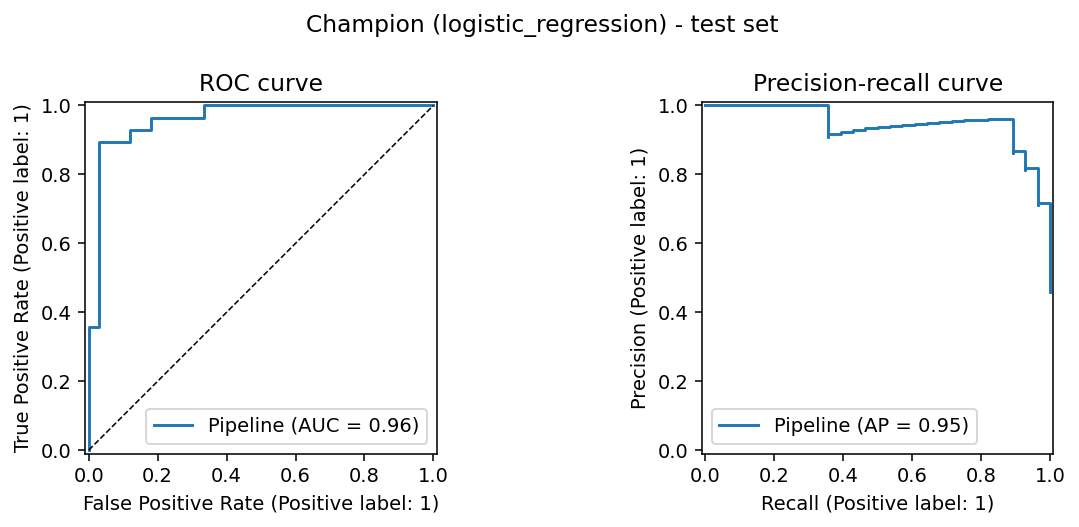

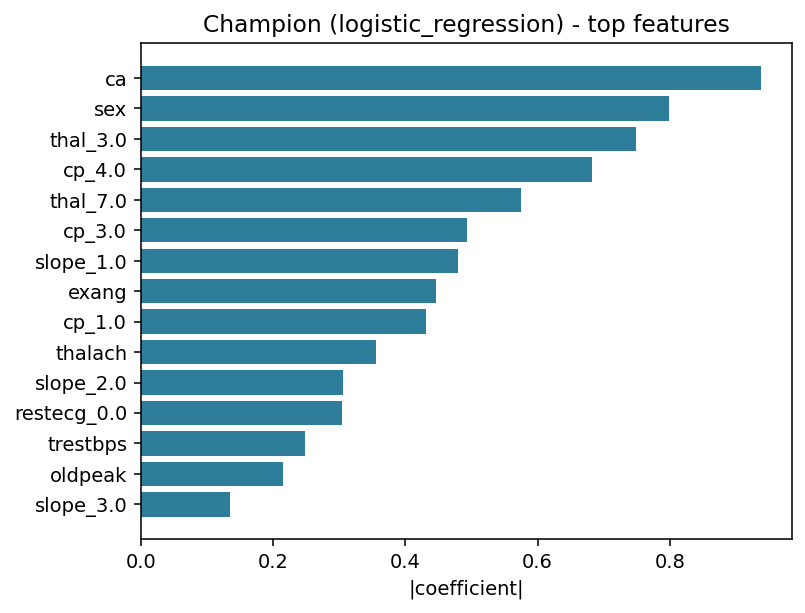

test_accuracy     0.869
test_precision    0.812
test_recall       0.929
test_f1           0.867
test_roc_auc      0.961
dtype: float64

In [8]:
for f in ["08_champion_confusion_matrix.png", "09_champion_roc_pr.png", "10_champion_feature_importance.png"]:
    display(Image(filename=str(ROOT / "reports/figures" / f), width=640))
pd.Series(meta["test_metrics"]).round(3)

**Why logistic regression wins:** with 242 training rows and mostly additive, monotonic risk factors, a regularised linear model matches or beats the ensembles on CV ROC-AUC and has lower variance across folds. It is also interpretable (coefficients) and tiny to serve. The held-out test scores (61 patients) are higher than CV scores; with such a small test set that gap is within sampling noise, so CV is the more reliable estimate and was used for selection.